# Visualisasi Data dengan Matplotlib

Tugas 3 Pengantar Sains Data

Visualisasi data transaksi menggunakan Matplotlib berdasarkan data transaksi POS tahun 2024–2025.

## 1. Import Library

Library yang digunakan adalah Pandas untuk mengolah data dan Matplotlib untuk membuat visualisasi.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Membaca Dataset

Dataset yang digunakan adalah data transaksi POS tahun 2024–2025.

In [2]:
df = pd.read_csv("dataset/paket_a_transaksi_pos_2024_2025.csv")

df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


## 3. Pembersihan Data

Data dibersihkan terlebih dahulu agar dapat digunakan untuk proses visualisasi. Tahapan yang dilakukan meliputi mengubah format tanggal, membersihkan harga, memperbaiki jumlah barang, mengisi kode kasir yang kosong, menghapus data duplikat, dan menghapus transaksi dengan jumlah barang lebih dari 12.

In [3]:
df["tanggal"] = pd.to_datetime(
    df["tanggal"],
    format="mixed",
    dayfirst=True
)

df["harga_satuan"] = pd.to_numeric(
    df["harga_satuan"].astype(str).str.replace(",", ".", regex=False)
)

df.loc[df["jumlah"] < 0, "jumlah"] = df.loc[df["jumlah"] < 0, "jumlah"].abs()

df["kode_kasir"] = df["kode_kasir"].fillna("K_UNKNOWN")

df = df.drop_duplicates()

df = df[df["jumlah"] <= 12]

## 4. Membuat Kolom Pendapatan dan Tahun

Kolom pendapatan digunakan untuk menghitung nilai penjualan setelah diskon dan PPN 11%. Kolom tahun digunakan untuk memisahkan data berdasarkan tahun transaksi.

In [4]:
df["Total_Kotor"] = df["jumlah"] * df["harga_satuan"]

df["Nominal_Diskon"] = (
    df["Total_Kotor"] * df["diskon_persen"] / 100
)

df["pendapatan"] = (
    df["Total_Kotor"] - df["Nominal_Diskon"]
) * 1.11

df["tahun"] = df["tanggal"].dt.year

ds = df.copy()

# Visualisasi Data

Visualisasi dilakukan menggunakan data transaksi tahun 2025. Terdapat empat visualisasi, yaitu penjualan per bulan, 10 produk terlaris, proporsi status transaksi, serta hubungan jumlah pembelian dengan diskon.

## 5. Penjualan per Bulan Tahun 2025

Grafik garis digunakan untuk melihat perubahan jumlah penjualan setiap bulan selama tahun 2025. Data yang digunakan hanya transaksi dengan status SELESAI.

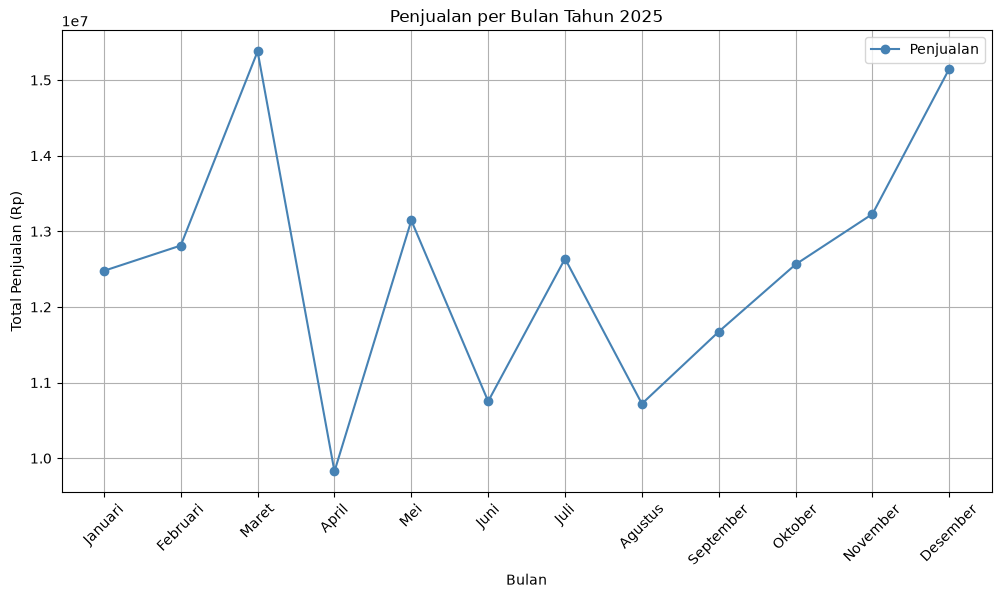

In [5]:
penjualan_bulanan = ds[
    (ds["tahun"] == 2025) &
    (ds["status"] == "SELESAI")
].groupby(
    ds["tanggal"].dt.month
)["pendapatan"].sum()

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli", "Agustus",
    "September", "Oktober", "November", "Desember"
]

plt.figure(figsize=(12, 6))

plt.plot(
    penjualan_bulanan.index,
    penjualan_bulanan.values,
    marker="o",
    color="steelblue",
    label="Penjualan"
)

plt.xticks(range(1, 13), bulan, rotation=45)
plt.title("Penjualan per Bulan Tahun 2025")
plt.xlabel("Bulan")
plt.ylabel("Total Penjualan (Rp)")
plt.grid(True)
plt.legend()

plt.show()

## 6. 10 Produk Terlaris Tahun 2025

Grafik batang digunakan untuk menampilkan 10 produk dengan jumlah pembelian terbanyak pada tahun 2025. Produk diurutkan berdasarkan total jumlah barang yang terjual.

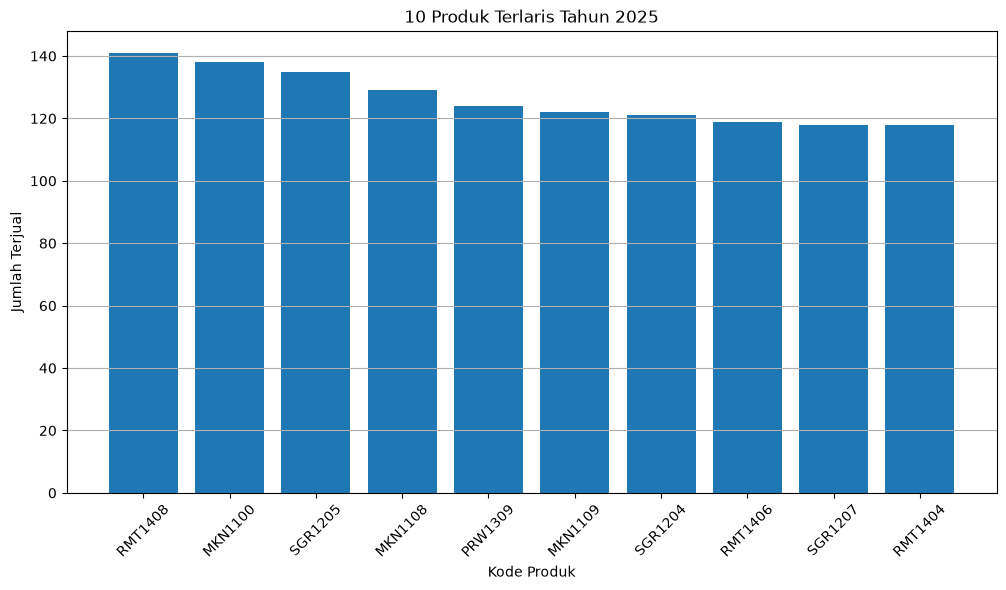

In [6]:
produk_terlaris = ds[
    (ds["tahun"] == 2025) &
    (ds["status"] == "SELESAI")
].groupby("kode_produk")["jumlah"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    produk_terlaris.index,
    produk_terlaris.values
)

plt.title("10 Produk Terlaris Tahun 2025")
plt.xlabel("Kode Produk")
plt.ylabel("Jumlah Terjual")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

## 7. Proporsi Transaksi Berhasil dan Gagal/Cancel

Diagram pie digunakan untuk melihat proporsi setiap status transaksi pada tahun 2025.

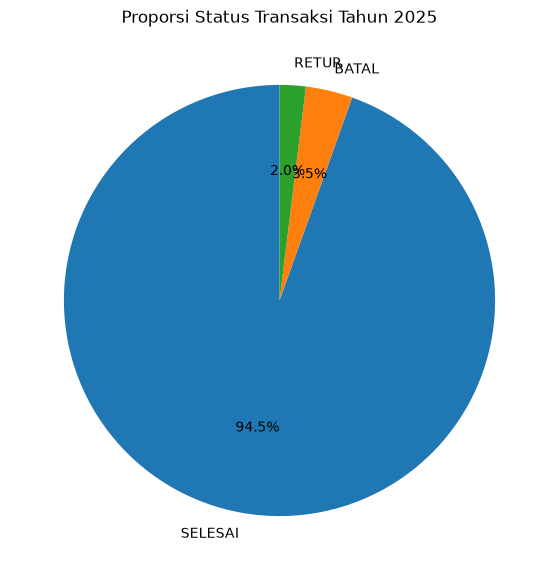

In [7]:
status_transaksi = ds[
    ds["tahun"] == 2025
]["status"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    status_transaksi.values,
    labels=status_transaksi.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Proporsi Status Transaksi Tahun 2025")

plt.show()

## 8. Hubungan Jumlah Beli dengan Diskon

Scatter plot digunakan untuk melihat hubungan antara jumlah barang yang dibeli dengan persentase diskon. Jitter ditambahkan agar titik data yang memiliki nilai sama tidak bertumpuk.

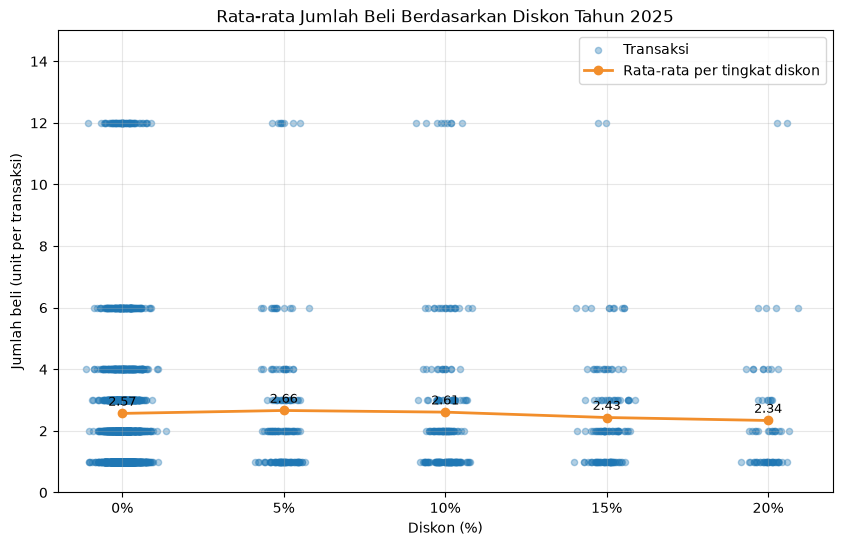

In [14]:
import numpy as np
import matplotlib.pyplot as plt

data_2025 = ds[ds["tahun"] == 2025].copy()

rata_rata = data_2025.groupby("diskon_persen")["jumlah"].mean()

np.random.seed(42)

x_jitter = (
    data_2025["diskon_persen"]
    + np.random.normal(0, 0.35, len(data_2025))
)

plt.figure(figsize=(10, 6))

plt.scatter(
    x_jitter,
    data_2025["jumlah"],
    alpha=0.35,
    s=20,
    label="Transaksi"
)

plt.plot(
    rata_rata.index,
    rata_rata.values,
    color="#f28e2b",
    marker="o",
    linewidth=2,
    label="Rata-rata per tingkat diskon"
)

for diskon, rata in rata_rata.items():
    plt.text(
        diskon,
        rata + 0.25,
        f"{rata:.2f}",
        ha="center",
        fontsize=9
    )

plt.title("Rata-rata Jumlah Beli Berdasarkan Diskon Tahun 2025")

plt.xlabel("Diskon (%)")
plt.ylabel("Jumlah beli (unit per transaksi)")

plt.xticks(
    [0, 5, 10, 15, 20],
    ["0%", "5%", "10%", "15%", "20%"]
)

plt.xlim(-2, 22)
plt.ylim(0, 15)

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

## 9. Kesimpulan

Berdasarkan hasil visualisasi data transaksi tahun 2025, dapat dilihat perubahan penjualan pada setiap bulan, produk dengan jumlah penjualan tertinggi, proporsi status transaksi, serta hubungan antara jumlah pembelian dan diskon.

Visualisasi menggunakan Matplotlib membantu data transaksi menjadi lebih mudah dipahami melalui grafik garis, grafik batang, diagram pie, dan scatter plot.